# **Attention is all you need**

### RNN & LSTM 



- Issue with Vanishing Gradients 

- 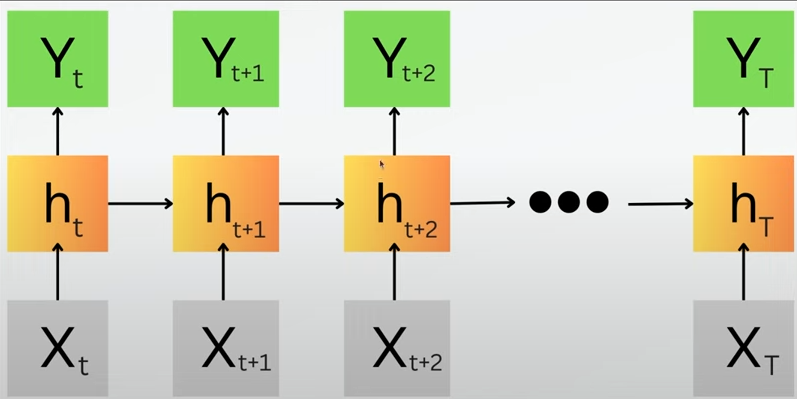


### Attention Augmented RNN

- Weighted Average of hidden states (by some weight)

- How are all others related to this time stamp "C" 

- expensive operation 

- "Attention" is all you need. RNN on inputs of Xs and then we are learning weights related to the history again. we are repeating steps. 
    The "C" are some kind of relationships 

- Sequence information no longer embedded (as a result moreoften we have to inject it)

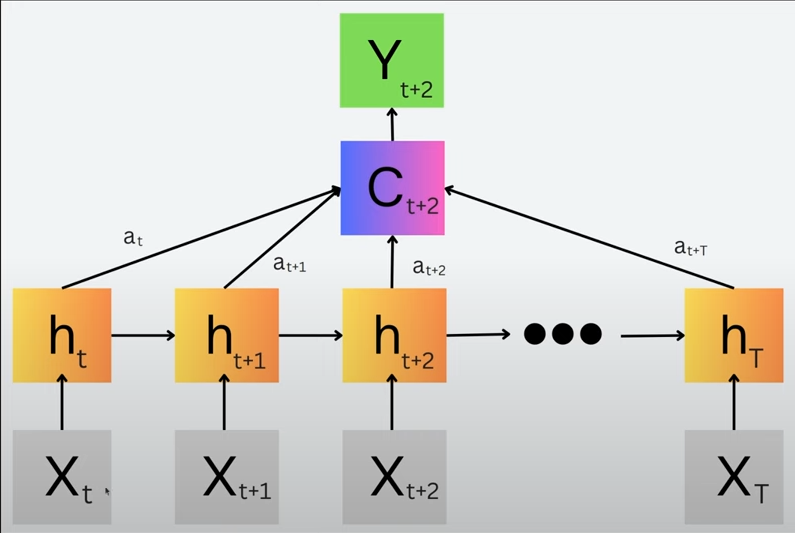

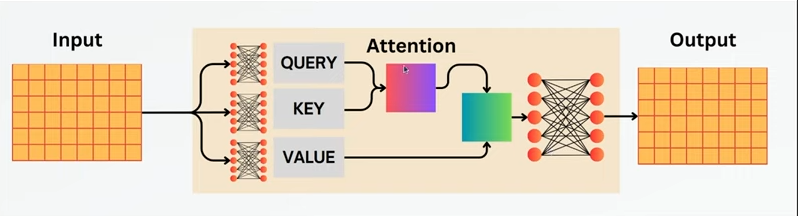

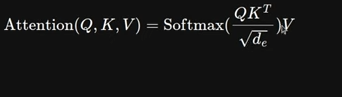

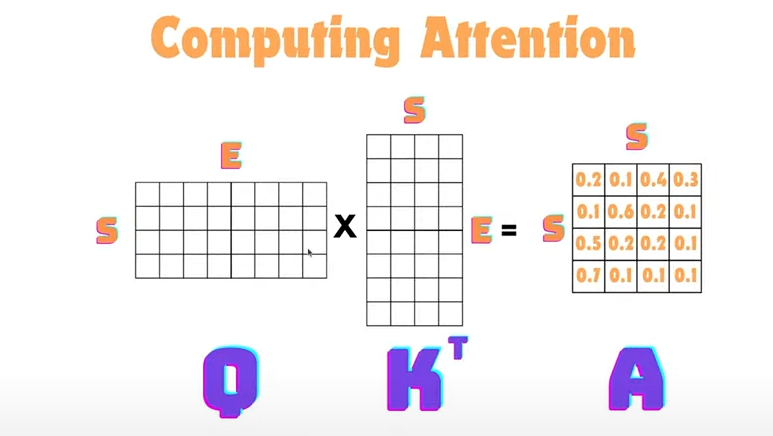

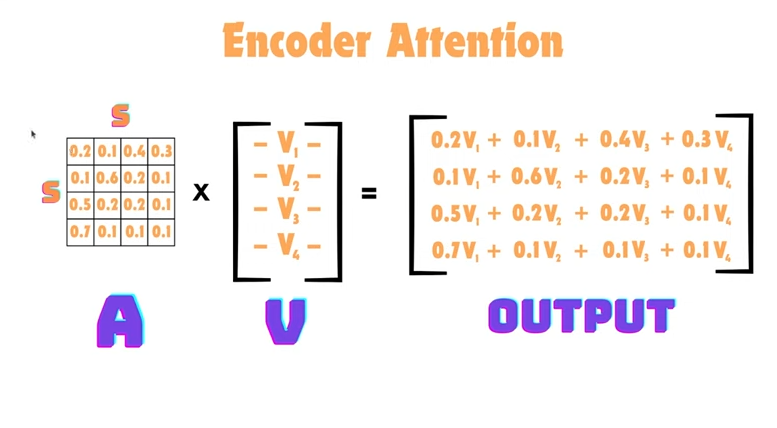

- Q X K.transpose  = Attentiion matrix Sequence by Sequence --> when the dot product is high they are pointing in the same direction and viceversa

- Attention matrix what are the relationships between tokens in sequence. 

- Q , K , V are all prokections of our Xs. 

- Context vectors 

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

batch_size = 4
sequence_length = 64
embed_dim = 128

x = torch.randn(batch_size , sequence_length , embed_dim)
print("Shape of Input is: " , x.shape)

Shape of Input is:  torch.Size([4, 64, 128])


In [26]:
x.shape

torch.Size([4, 64, 128])

In [27]:
(x.transpose(1,2)).shape

torch.Size([4, 128, 64])

In [28]:
similarity = (x @ x.transpose(1,2)) / (embed_dim**0.5)

#similarity.var() #mainn reason for normlization
attention_matrix = similarity.softmax(2) #needs dimension  1 --> columns -1,2 --> along rows and 0 -->  batch

atten = attention_matrix @ x
atten.shape

torch.Size([4, 64, 128])

In [29]:
atten

tensor([[[ 3.4911e-01,  5.4094e-01, -9.0704e-01,  ...,  1.2086e+00,
           1.4859e+00,  1.7311e+00],
         [-1.7991e+00, -9.0286e-01,  7.4127e-01,  ...,  2.4508e+00,
           4.9360e-01, -1.3833e+00],
         [ 3.1936e-01, -2.6605e-01,  3.0731e-01,  ..., -3.4177e-01,
          -2.7692e-01,  5.9343e-01],
         ...,
         [-3.4269e-01, -3.7159e-01,  8.7744e-01,  ...,  2.8669e-01,
           1.0219e+00,  1.1998e+00],
         [ 1.8681e-01, -1.0615e+00, -2.2198e+00,  ...,  1.7681e+00,
           1.2792e+00, -9.2715e-01],
         [ 8.8084e-01,  1.2628e+00, -1.2385e+00,  ..., -9.1888e-01,
          -1.7396e+00, -4.6428e-01]],

        [[-6.8554e-01, -1.0282e+00, -1.2600e-01,  ..., -9.3251e-01,
           7.5219e-02, -9.1977e-01],
         [-3.3497e-01, -4.7157e-02,  1.6822e+00,  ...,  3.7565e-01,
          -8.4094e-01, -7.3864e-01],
         [ 8.9760e-01, -3.4588e-01, -1.3625e+00,  ..., -1.2297e+00,
           6.5377e-01, -1.0321e+00],
         ...,
         [ 1.9541e-01, -5

In [34]:
linear = nn.Linear(10,20)
rand =torch.randn(4,6,10) # final dimension should match input
linear(rand).shape

torch.Size([4, 6, 20])

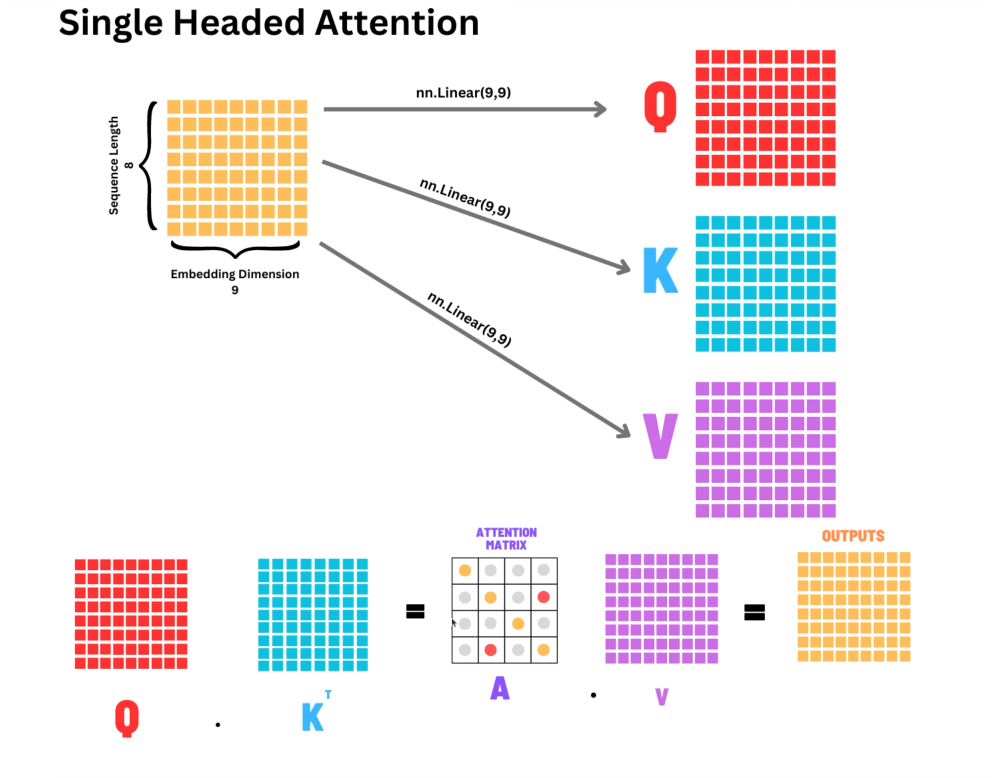

Words are related to each other from


One attention matrix may not be able to caputure al of this.

In [35]:
#A single Attention Head
class Attention(nn.Module):
  def __init__(self , embedding_dimension):

    super().__init__()

    self.embed_dim = embedding_dimension


    #Three projection of the exact same matix
    self.query = nn.Linear(self.embed_dim , self.embed_dim)
    self.key = nn.Linear(self.embed_dim , self.embed_dim)
    self.value = nn.Linear(self.embed_dim , self.embed_dim)

  def forward(self , x):
    print(x.shape)
    q = self.query(x)
    v = self.value(x)
    k = self.key(x)

    similarity = (q @ k.transpose(1,2)) / (embed_dim**0.5)
    attention_matrix = similarity.softmax(-1)
    output = attention_matrix @ v

    print(output.shape)



rand = torch.rand(4,64,128)
attn = Attention(embedding_dimension = 128)

attn(rand)

torch.Size([4, 64, 128])
torch.Size([4, 64, 128])


# **Multiple Head Attention**

We hope by using multiple head attention matrix we can learn different things about the data.

should divide evenly.

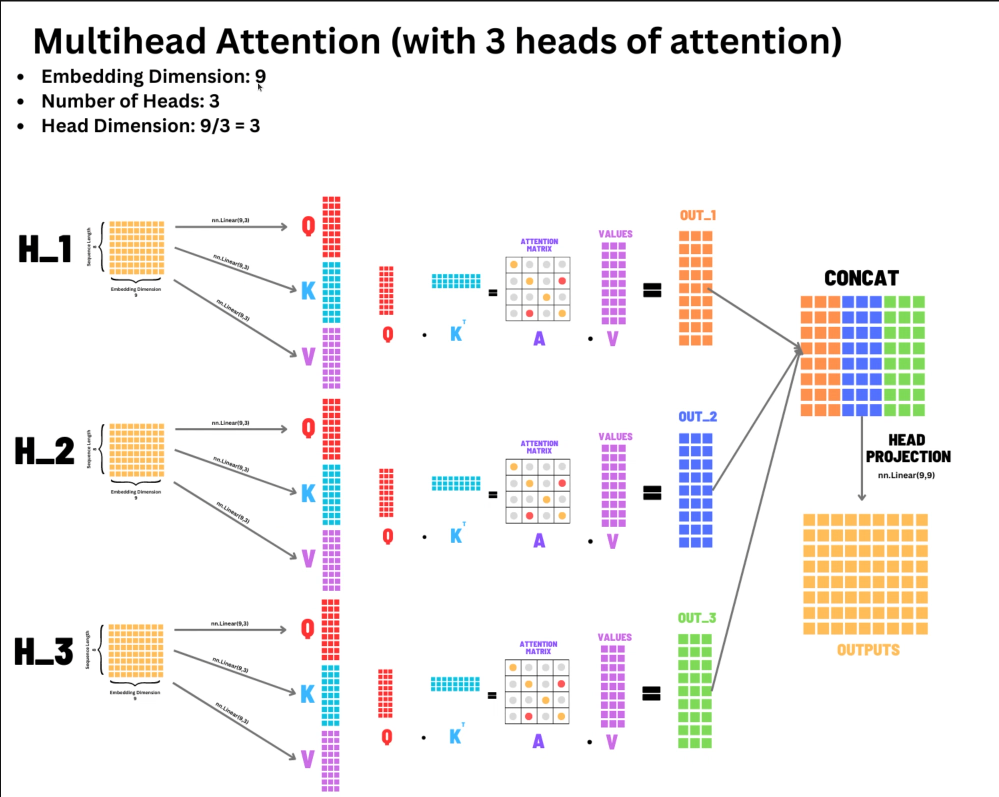

### Dumb way

- We want to avoid using "for" loop

In [39]:
class MultiheadAttention(nn.Module):

  def __init__(self , embedding_dimsension , num_heads):
    super().__init__()

    self.embed_dim = embedding_dimsension
    self.num_heads = num_heads

    self.head_dim = self.embed_dim // self.num_heads


    self.multihead_qkv = nn.ModuleList()

    for head in range(num_heads):
      qkv_proj = nn.ModuleDict([
                                ["Q" , nn.Linear(self.embed_dim , self.head_dim)],
                                ["K" , nn.Linear(self.embed_dim , self.head_dim)],
                                ["V" , nn.Linear(self.embed_dim , self.head_dim)]
                                ])
      self.multihead_qkv.append(qkv_proj)

    self.proj = nn.Linear(self.embed_dim , self.embed_dim) #just to make sure they know each other

  def forward(self , x):

      heads_out = []

      for head in self.multihead_qkv:
        q = head["Q"](x)
        k = head["K"](x)
        v = head["V"](x)

        similarity = (q @ k.transpose(1,2)) / (self.head_dim**0.5)
        attention_matrix = similarity.softmax(-1)
        output = attention_matrix @ v
        heads_out.append(output)


      heads_out = torch.cat(heads_out,dim=-1)
      out = self.proj(heads_out)
      print(out.shape)



rand = torch.randn(4,64,128)
attn = MultiheadAttention(128,4)
attn(rand)

torch.Size([4, 64, 128])


In [44]:
tensor = torch.randn(1,8,20)
fc = nn.Linear(20,20)


q = fc(tensor)

print(q.shape)

c1 ,c2 , c3 , c4 , c5= torch.chunk(q,5,axis=-1) #cut into pieces along the last axis

c1.shape

torch.Size([1, 8, 20])


torch.Size([1, 8, 4])

In [ ]:
a = torch.rand(5 ,2,6,4)
b = torch.rand(5,2,4,3)
#pytorch automatically flattens everything except the last two dimensions

In [45]:
class SelfAttentionEncoder(nn.Module):
  def __init__ (self , embed_dim , num_heads , attn_p = 0.0 , proj_p = 0.0):

    super().__init__()

    self.embed_dim = embed_dim
    self.num_heads = num_heads
    self.head_dims = embed_dim //num_heads

    self.query = nn.Linear(embed_dim , embed_dim)
    self.value = nn.Linear(embed_dim , embed_dim)
    self.key = nn.Linear(embed_dim , embed_dim)
    self.attn_drop = nn.Dropout(attn_p)
    self.proj_drop = nn.Dropout(proj_p)
    self.proj = nn.Linear(self.embed_dim , self.embed_dim)

  def forward(self , x):


    batch_size , seq_len , embed_dim = x.shape
    q = self.query(x).reshape(batch_size,seq_len , self.num_heads , self.head_dims).transpose(1,2)
    k = self.query(x).reshape(batch_size,seq_len , self.num_heads , self.head_dims).transpose(1,2)
    v = self.query(x).reshape(batch_size,seq_len , self.num_heads , self.head_dims).transpose(1,2)

    attn = (q@k.transpose(-2,-1))* self.head_dims**0.5
    #print(attn.shape)
    attn = attn.softmax(axis=-1)
    #print(attn.shape)
    attn = self.attn_drop(attn)
    #print(v.shape)
    #print(attn.shape)
    x = attn @ v
    x = x.transpose(1,2).reshape(batch_size , seq_len , embed_dim)
    print(x.shape)

    X = self.proj(x)
    X = self.proj_drop(x)

    return X

rand = torch.rand(4,16,128)
attn = SelfAttentionEncoder(128 , 4)
attn(rand)

torch.Size([4, 16, 128])


tensor([[[-0.1511, -0.7307, -0.5646,  ..., -0.7991, -0.0979, -0.3099],
         [-0.1494, -0.6290, -0.6052,  ..., -0.6139, -0.2207, -0.2407],
         [-0.1180, -0.5997, -0.5982,  ..., -0.5233, -0.1470, -0.3003],
         ...,
         [-0.1998, -0.4439, -0.5037,  ..., -0.5362,  0.0027, -0.1183],
         [-0.1670, -0.5897, -0.6049,  ..., -0.6209, -0.2360, -0.2467],
         [-0.2237, -0.5774, -0.5739,  ..., -0.4634, -0.0338, -0.4938]],

        [[-0.2035, -0.8362, -0.2541,  ..., -0.4229, -0.2545, -0.6357],
         [-0.3125, -0.8426, -0.2277,  ..., -0.3810, -0.1194, -0.1842],
         [-0.2358, -0.8569, -0.3240,  ..., -0.4636, -0.1705, -0.5447],
         ...,
         [-0.3431, -0.8888, -0.2193,  ..., -0.5421, -0.0201, -0.2279],
         [-0.1482, -0.6896, -0.4358,  ..., -0.4676, -0.1295, -0.4583],
         [-0.1160, -0.7216, -0.6131,  ..., -0.4121, -0.1130, -0.3838]],

        [[-0.2225, -0.7188, -0.5600,  ..., -0.4630, -0.0668, -0.2420],
         [-0.0188, -0.7255, -0.6388,  ..., -0

# **Padding**

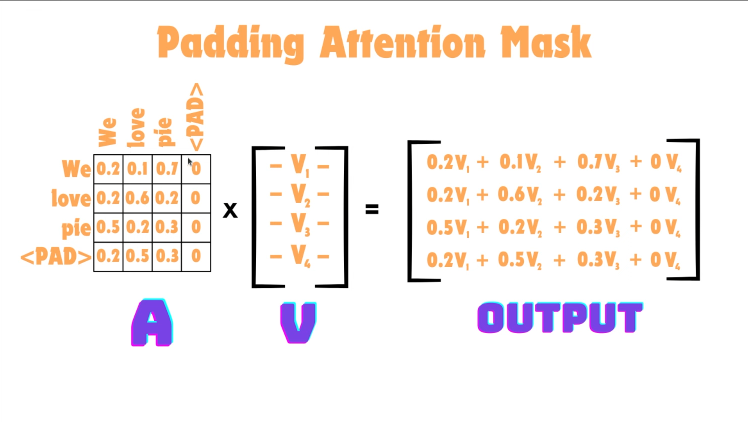

- padding 

- Language specific problem as sentences are not of the same length.

- Attention Mask 

- We want to ignore relationships with pad.  token --> pad   , pad --> token ( we want to learn this )

- We will zero out the columns to all Pad Tokens 

- X = [10,2,<pad>]

- 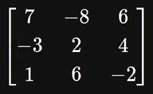

- We also need to make sure the probability sums up to one.

- In order to zero out we fill with -Inf then doinf softmax takes them to zero. 

- padding mask 

In [59]:

rand_attn = torch.rand(1,6,6)

attention_mask = torch.tensor([1,1,1,1,0,0]).unsqueeze(0).bool()
print(attention_mask)



tensor([[ True,  True,  True,  True, False, False]])


In [60]:
#Method 1

attention_mask = attention_mask.unsqueeze(1)

masking = torch.softmax(rand_attn.masked_fill_(~attention_mask , -float("inf")) , axis= -1)


print(attention_mask.shape)

print(rand_attn.shape)

print(masking)

torch.Size([1, 1, 6])
torch.Size([1, 6, 6])
tensor([[[0.3268, 0.2557, 0.1689, 0.2486, 0.0000, 0.0000],
         [0.1600, 0.3685, 0.1975, 0.2740, 0.0000, 0.0000],
         [0.3378, 0.2065, 0.3081, 0.1476, 0.0000, 0.0000],
         [0.2792, 0.2238, 0.2254, 0.2716, 0.0000, 0.0000],
         [0.2928, 0.1453, 0.2831, 0.2788, 0.0000, 0.0000],
         [0.2847, 0.1986, 0.3311, 0.1856, 0.0000, 0.0000]]])


In [63]:
# second method
attention_mask = torch.tensor([1,1,1,1,0,0]).unsqueeze(0).bool()
attention_mask = attention_mask.unsqueeze(1).repeat(1,6,1)

print(attention_mask)

tensor([[[ True,  True,  True,  True, False, False],
         [ True,  True,  True,  True, False, False],
         [ True,  True,  True,  True, False, False],
         [ True,  True,  True,  True, False, False],
         [ True,  True,  True,  True, False, False],
         [ True,  True,  True,  True, False, False]]])


In [67]:
rand_attn = torch.rand(1,2,6,6)
attention_mask = torch.tensor([1,1,1,1,0,0]).unsqueeze(0).bool()
attention_mask = attention_mask.unsqueeze(1).unsqueeze(2)
attention_mask = attention_mask.repeat(1,1,6,1)
attention_mask

tensor([[[[ True,  True,  True,  True, False, False],
          [ True,  True,  True,  True, False, False],
          [ True,  True,  True,  True, False, False],
          [ True,  True,  True,  True, False, False],
          [ True,  True,  True,  True, False, False],
          [ True,  True,  True,  True, False, False]]]])

In [65]:
rand_attn.masked_fill_(~attention_mask , -float("inf"))

tensor([[[[0.0461, 0.2069, 0.0702, 0.4995,   -inf,   -inf],
          [0.3678, 0.5933, 0.2059, 0.4088,   -inf,   -inf],
          [0.0700, 0.8979, 0.2412, 0.7754,   -inf,   -inf],
          [0.1435, 0.0652, 0.6069, 0.0241,   -inf,   -inf],
          [0.4225, 0.1243, 0.0050, 0.8082,   -inf,   -inf],
          [0.6322, 0.8567, 0.4557, 0.9641,   -inf,   -inf]],

         [[0.2834, 0.2338, 0.6997, 0.3949,   -inf,   -inf],
          [0.6610, 0.8491, 0.6326, 0.8961,   -inf,   -inf],
          [0.5397, 0.6343, 0.1534, 0.4123,   -inf,   -inf],
          [0.5635, 0.9201, 0.3042, 0.1905,   -inf,   -inf],
          [0.2961, 0.5843, 0.6503, 0.6387,   -inf,   -inf],
          [0.6187, 0.0773, 0.5350, 0.0542,   -inf,   -inf]]]])

In [79]:
class SelfAttentionEncoder(nn.Module):
  def __init__ (self , embed_dim , num_heads , attn_p = 0.0 , proj_p = 0.0):

    super().__init__()

    self.embed_dim = embed_dim
    self.num_heads = num_heads
    self.head_dims = embed_dim //num_heads

    self.query = nn.Linear(embed_dim , embed_dim)
    self.value = nn.Linear(embed_dim , embed_dim)
    self.key = nn.Linear(embed_dim , embed_dim)
    self.attn_drop = nn.Dropout(attn_p)
    self.proj_drop = nn.Dropout(proj_p)
    self.proj = nn.Linear(self.embed_dim , self.embed_dim)

  def forward(self , x , attention_mask = None) :


    batch_size , seq_len , embed_dim = x.shape
    q = self.query(x).reshape(batch_size,seq_len , self.num_heads , self.head_dims).transpose(1,2)
    k = self.query(x).reshape(batch_size,seq_len , self.num_heads , self.head_dims).transpose(1,2)
    v = self.query(x).reshape(batch_size,seq_len , self.num_heads , self.head_dims).transpose(1,2)

    attn = (q@k.transpose(-2,-1))* self.head_dims**0.5
    #print(attn.shape)
  ##############################################
  #############################################

  ##### for padding ##########################

    if attention_mask is not None:
     attention_mask = attention_mask.unsqueeze(1).unsqueeze(1).repeat(1,1,seq_len,1)
     attn.masked_fill_(~attention_mask , -float("inf"))
     

  ############################################
  ############################################


    attn = attn.softmax(axis=-1)
    #print(attn.shape)
    attn = self.attn_drop(attn)
    #print(v.shape)
    
    x = attn @ v
    x = x.transpose(1,2).reshape(batch_size , seq_len , embed_dim)
    print(x.shape)
    
    X = self.proj(x)
    X = self.proj_drop(x)

    return X






In [80]:
seq_lens = [3,5,4]
embed_dim = 9
num_heads = 3

a = SelfAttentionEncoder(embed_dim , num_heads)


rand = torch.rand(len(seq_lens) , max(seq_lens) , embed_dim)
masks = torch.nn.utils.rnn.pad_sequence([torch.ones(l) for l in seq_lens], batch_first =True  , padding_value = 0).bool()


output = a (rand , masks)

torch.Size([3, 5, 9])


### Causal Masking

- Can only Look at the past to predict the future.

- convert top right column along diagonal to zero by filling with negative infinity 

- 

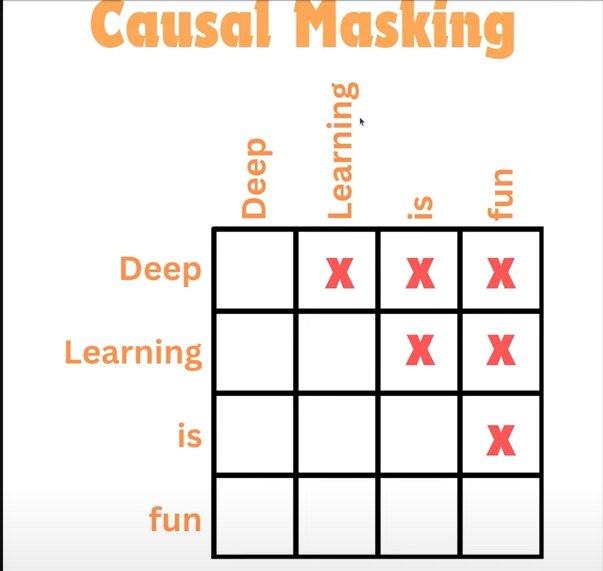

In [82]:
seq_len = 8


ones = torch.ones((seq_len,seq_len))
causal_mask = torch.tril(ones).bool()

padding_mask = torch.tensor([1,1,1,1,0,0,0,0]).bool()
padding_mask = padding_mask.unsqueeze(0).repeat(seq_len,1)

causal_mask = causal_mask.masked_fill(~padding_mask , 0)

causal_mask

tensor([[ True, False, False, False, False, False, False, False],
        [ True,  True, False, False, False, False, False, False],
        [ True,  True,  True, False, False, False, False, False],
        [ True,  True,  True,  True, False, False, False, False],
        [ True,  True,  True,  True, False, False, False, False],
        [ True,  True,  True,  True, False, False, False, False],
        [ True,  True,  True,  True, False, False, False, False],
        [ True,  True,  True,  True, False, False, False, False]])

In [ ]:
class SelfAttentionEncoder(nn.Module):
  def __init__ (self , embed_dim , num_heads, causal = False , attn_p = 0.0 , proj_p = 0.0 , bias = True):

    super().__init__()

    self.embed_dim = embed_dim
    self.num_heads = num_heads
    self.head_dims = embed_dim //num_heads
    self.causal = causal
    self.query = nn.Linear(embed_dim , embed_dim)
    self.value = nn.Linear(embed_dim , embed_dim)
    self.key = nn.Linear(embed_dim , embed_dim)
    self.attn_drop = nn.Dropout(attn_p)
    self.proj_drop = nn.Dropout(proj_p)
    self.proj = nn.Linear(self.embed_dim , self.embed_dim)
  

  def forward(self , x , attention_mask) :


    batch_size , seq_len , embed_dim = x.shape
    q = self.query(x).reshape(batch_size,seq_len , self.num_heads , self.head_dims).transpose(1,2)
    k = self.query(x).reshape(batch_size,seq_len , self.num_heads , self.head_dims).transpose(1,2)
    v = self.query(x).reshape(batch_size,seq_len , self.num_heads , self.head_dims).transpose(1,2)

    attn = (q@k.transpose(-2,-1))* self.head_dims**0.5
    #print(attn.shape)

  #############################################
    if attention_mask is not None:
      attention_mask = attention_mask.unsqueeze(1).unsqueeze(1).repeat(1,1,seq_len,1)

    if self.causal:
      ones = torch.ones((seq_len , seq_len) , device =attn.device)
      causal_mask = torch.tril(ones).bool()
      causal_mask = causal_mask.reshape(1,1,seq_len , seq_len)
      #print(causal_mask)
  ##############################################
  #############################################
      if attention_mask is not None:
        causal_mask = causal_mask.repeat(batch_size , 1,1,1)
        causal_mask = causal_mask.masked_fill(~attention_mask , False)
        # print(attention_mask.shape)
        print(causal_mask)
    attn.masked_fill_(~attention_mask , -float("inf"))



  ############################################
  ############################################


    attn = attn.softmax(axis=-1)
    #print(attn.shape)
    attn = self.attn_drop(attn)
    #print(v.shape)
    #print(attn[0])
    x = attn @ v
    x = x.transpose(1,2).reshape(batch_size , tgt_len , embed_dim)
    #print(x.shape)
    #print(x[0])
    x = self.proj(x)
    x = self.proj_drop(x)
    print(x.shape)

    return x




seq_lens = [3,5,4]
embed_dim = 9
num_heads = 3

a = SelfAttentionEncoder(embed_dim , num_heads,causal = True)


rand = torch.rand(len(seq_lens) , max(seq_lens) , embed_dim)
masks = torch.nn.utils.rnn.pad_sequence([torch.ones(l) for l in seq_lens], batch_first =True  , padding_value = 0).bool()

#print(masks)

output = a (rand , masks)

tensor([[[[ True, False, False, False, False],
          [ True,  True, False, False, False],
          [ True,  True,  True, False, False],
          [ True,  True,  True, False, False],
          [ True,  True,  True, False, False]]],


        [[[ True, False, False, False, False],
          [ True,  True, False, False, False],
          [ True,  True,  True, False, False],
          [ True,  True,  True,  True, False],
          [ True,  True,  True,  True,  True]]],


        [[[ True, False, False, False, False],
          [ True,  True, False, False, False],
          [ True,  True,  True, False, False],
          [ True,  True,  True,  True, False],
          [ True,  True,  True,  True, False]]]])
torch.Size([3, 5, 9])


### Cross Attention

 - Cross attention --> How is everything releted the change in modality

- English --> French

- we will learn how english to english , fench to french and english to french 

- Embedding dimension is same but sequence length may differ 

- Query is what we want , Keys and Values is what we want to weigh against.



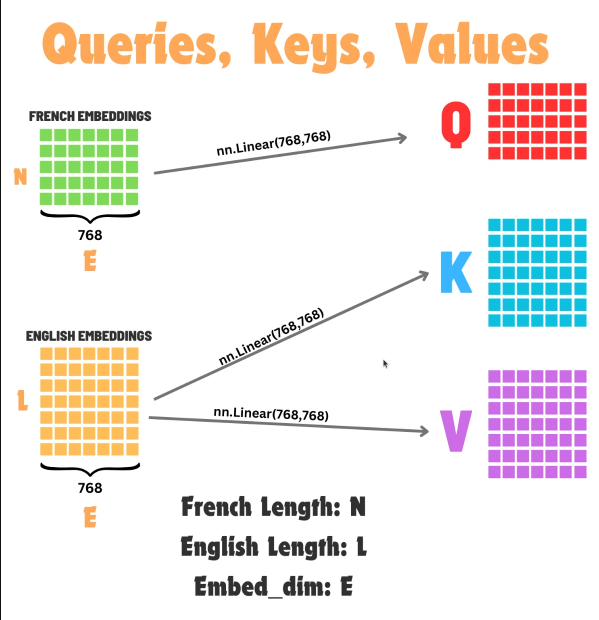

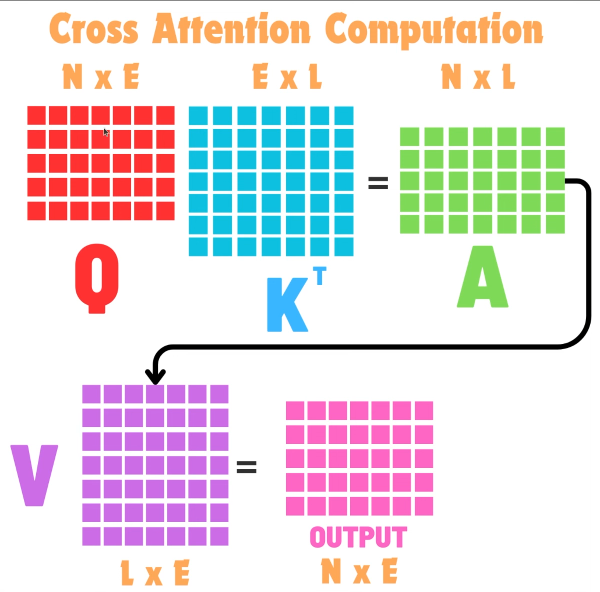

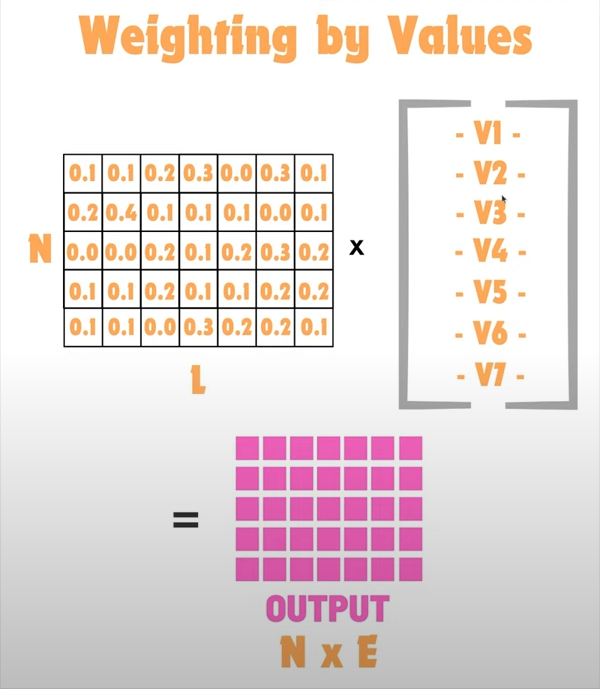

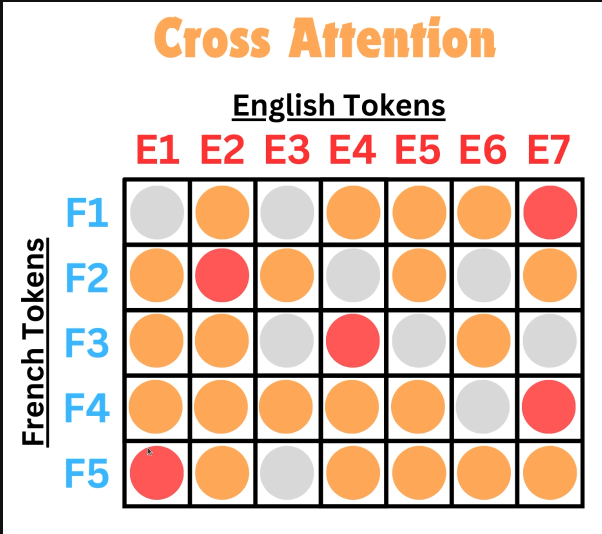

In [100]:
class CrossAttention(nn.Module):
  def __init__ (self , embed_dim , num_heads, causal = False , attn_p = 0.0 , proj_p = 0.0):

    super().__init__()

    self.embed_dim = embed_dim
    self.num_heads = num_heads
    self.head_dims = embed_dim //num_heads
    self.causal = causal
    self.query = nn.Linear(embed_dim , embed_dim)
    self.value = nn.Linear(embed_dim , embed_dim)
    self.key = nn.Linear(embed_dim , embed_dim)
    self.attn_drop = nn.Dropout(attn_p)
    self.proj_drop = nn.Dropout(proj_p)
    self.proj = nn.Linear(self.embed_dim , self.embed_dim)

  def forward(self , src , tgt, attention_mask):


    batch_size , src_len , embed_dim = src.shape
    batch_size , tgt_len , embed_dim = tgt.shape


    q = self.query(tgt).reshape(batch_size,tgt_len , self.num_heads , self.head_dims).transpose(1,2)
    k = self.query(src).reshape(batch_size,src_len , self.num_heads , self.head_dims).transpose(1,2)
    v = self.query(src).reshape(batch_size,src_len , self.num_heads , self.head_dims).transpose(1,2)

    attn = (q@k.transpose(-2,-1))* self.head_dims**0.5

  #############################################
    if attention_mask is not None:
      attention_mask = attention_mask.unsqueeze(1).unsqueeze(1).repeat(1,1,tgt_len,1)
      attention_mask = attention_mask.masked_fill_(~attention_mask , -float("inf"))

      print(attention_mask.shape)




  ############################################
  ############################################


    attn = attn.softmax(axis=-1)
    #print(attn.shape)
    attn = self.attn_drop(attn)
    #print(v.shape)
    #print(attn[0])
    x = attn @ v
    x = x.transpose(1,2).reshape(batch_size , tgt_len , embed_dim)

    print(x.shape)
    #print(x.shape)
    #print(x[0])
    X = self.proj(x)
    X = self.proj_drop(x)
    #print(X.shape)

    return X




### We will now have sequences of different lengths, identify the number of tokens in each sequence ###
english_seq_lens = [3,5,4]
french_seq_lens = [7,6,2]

embed_dim = 18
num_heads = 3
#a = CrossAttention(embed_dim, num_heads)

### Create random tensor in the shape (Batch x Seq Len x Embed Dim) for French and English ###
### This will be a tensor upto the max(seq_lens) ###
rand_english = torch.randn(len(english_seq_lens),max(english_seq_lens),embed_dim)
rand_french = torch.randn(len(french_seq_lens),max(french_seq_lens),embed_dim)


### Create Attention Mask from the seq_lens (shortest sequences padded to the longest ###
english_masks = torch.nn.utils.rnn.pad_sequence([torch.ones(l) for l in english_seq_lens], batch_first=True, padding_value=0).bool()
french_masks = torch.nn.utils.rnn.pad_sequence([torch.ones(l) for l in french_seq_lens], batch_first=True, padding_value=0).bool()

# print("English Attention Mask:")
# print(english_masks)
# print("French Attention Mask:")
# print(french_masks)

a(src=rand_english, tgt=rand_french, attention_mask=french_masks)
# ### Pass through MHA ###
# output = a(src=rand_english, tgt=rand_french, attention_mask=english_masks)
# print("Final Output:", output.shape)

torch.Size([3, 7, 18])


tensor([[[-1.6219e-01, -2.8008e-01,  4.8907e-01,  6.2783e-01,  8.7056e-01,
          -1.2125e+00,  5.0461e-01, -6.7957e-02,  3.9594e-01, -3.2983e-01,
          -7.4453e-01, -6.3979e-01,  4.0967e-01, -4.0463e-01, -4.2518e-01,
          -4.9093e-01,  1.7083e-02, -4.4639e-01],
         [-4.0715e-01, -3.5991e-01,  5.6045e-01, -7.6174e-01,  7.3786e-01,
          -9.4400e-01,  1.9635e-01,  2.1790e-01, -1.8377e-01,  1.2664e-01,
          -2.1401e-01, -3.2715e-01, -4.8155e-01, -3.6184e-02, -1.3472e-01,
          -3.2795e-01, -3.3886e-02, -2.7899e-01],
         [ 6.2361e-01, -2.6002e-01, -7.5986e-01,  8.9145e-01, -3.1813e-01,
           4.2601e-01, -3.3794e-01, -4.9100e-02, -3.4749e-01,  4.7456e-01,
           1.0781e-01,  1.7555e-01, -4.8690e-01, -8.0141e-02,  1.9877e-02,
          -1.2108e-01,  2.9956e-02, -2.4823e-01],
         [ 4.3462e-01, -2.1730e-01, -4.5460e-01,  7.4731e-01, -7.3258e-02,
          -1.9514e-03,  1.0412e-01,  6.2703e-01,  1.3159e-02,  2.6239e-01,
           2.3875e-02, -2

### **Flash Attention**

- Issues with Normal Attenitons

- Quadratic Complexity: The sizes of each matrix grows so much.

- Fused Kernel 

- cuda

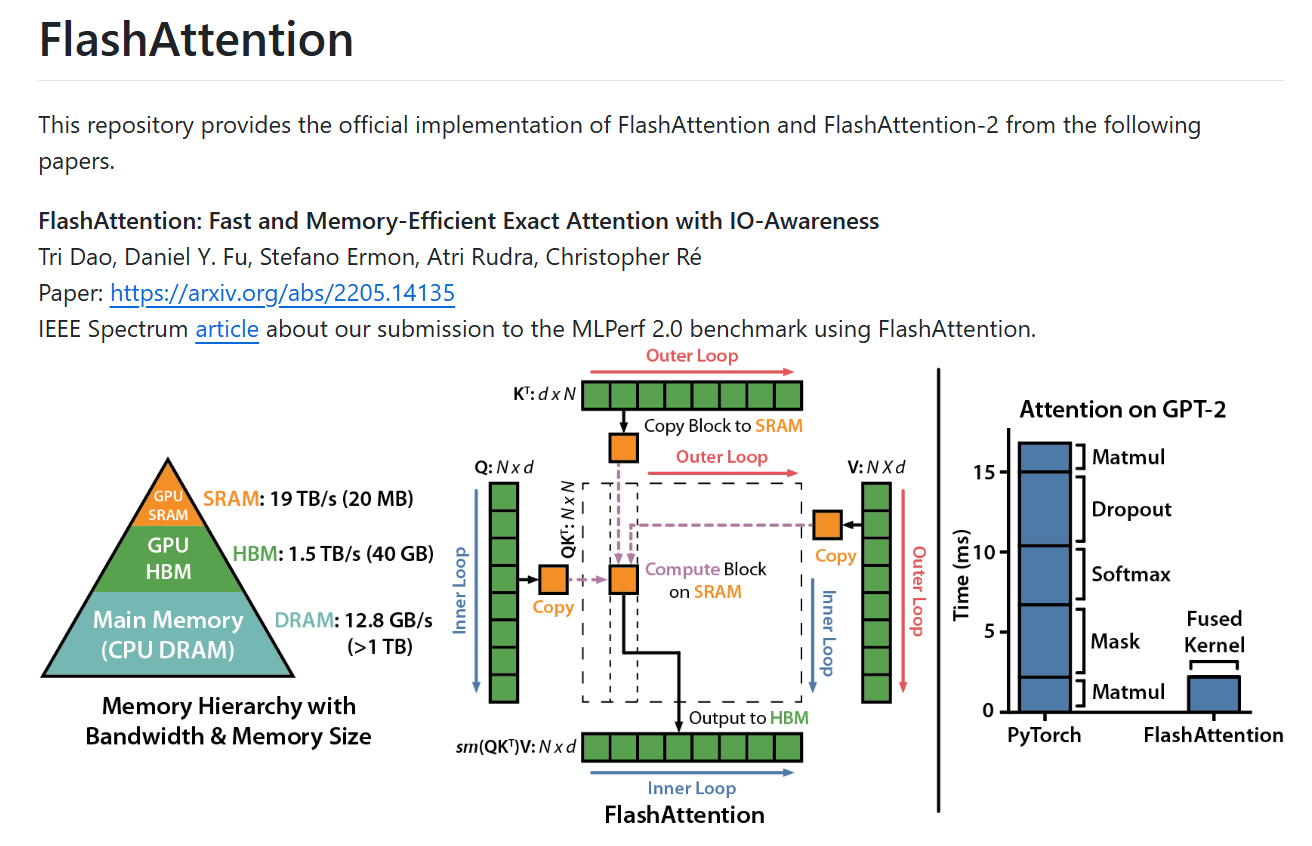

# Master Attention Code

In [ ]:
pip install flashattention 

In [5]:
class Attention(nn.Module):

  def __init__(self , embed_dim=768 , num_heads=12 , attn_dropout=0.0 , proj_drop=0.0):

        super(Attention , self).__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.attn_dropout = attn_dropout
        assert embed_dim % num_heads ==0 , "Make sure embed dim divisible by num heads"
        self.head_dims = self.embed_dim // self.num_heads

        self.q_proj = nn.Linear(embed_dim , embed_dim)
        self.k_proj = nn.Linear(embed_dim , embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim , embed_dim)
        self.proj_drop = nn.Dropout(proj_drop)

  def forward(self
              ,src # if only src its self attention
              , tgt = None ,  #  if we have a target we have cross attention 
              attention_mask = None,
              causal= False):

        batch_size , src_len , embed_dim = src.shape
        #self attention
        if tgt is None:

            q = self.q_proj(src).reshape(batch_size,src_len , self.num_heads , self.head_dims).transpose(1,2)
            k = self.k_proj(src).reshape(batch_size,src_len , self.num_heads , self.head_dims).transpose(1,2)
            v = self.v_proj(src).reshape(batch_size,src_len , self.num_heads , self.head_dims).transpose(1,2)

            if attention_mask is not None:

              attention_mask = attention_mask.bool()
              attention_mask = attention_mask.unsqueeze(1).unsqueeze(1).repeat(1,1,src_len,1) #flash attention expects this --> pytorch version vs flash version
              attention_out = F.scaled_dot_product_attention(q,k,v,
                                                             attn_mask = attention_mask,
                                                             dropout_p=self.attn_dropout if self.train else 0.0 ,
                                                             is_causal = causal)

        #cross attention
        else:
          tgt_len = tgt.shape[1]

          q = self.q_proj(tgt).reshape(batch_size,tgt_len , self.num_heads , self.head_dims).transpose(1,2)
          k = self.k_proj(src).reshape(batch_size,src_len , self.num_heads , self.head_dims).transpose(1,2)
          v = self.v_proj(src).reshape(batch_size,src_len , self.num_heads , self.head_dims).transpose(1,2)

          if attention_mask is not None:


              attention_mask = attention_mask.bool()
              attention_mask = attention_mask.unsqueeze(1).unsqueeze(1).repeat(1,1,tgt_len,1) #flash attention expects this --> pytorch version vs flash version
              attention_out = F.scaled_dot_product_attention(q,k,v,attn_mask = attention_mask,
                                                              dropout_p=self.attn_dropout if self.train else 0.0 ,
                                                                is_causal = False)



        #print(attn.shape)

        attention_out = attention_out.transpose(1,2).flatten(2) # (B X H X S X E) --> (B X S X H X E)  Flatten everything from 2 onwards (H AND E to the end )
        attention_out = self.proj_drop(attention_out)
        attention_out = self.out_proj(attention_out)
        

        return attention_out



In [6]:
### Test Out Self-Attention!! ###
print("TESTING SELF-ATTENTION!!!")
print("-------------------------")
seq_lens = [3,5,4]
embed_dim = 9
num_heads = 3
a = Attention(embed_dim, num_heads)

### Create a random tensor in the shape (Batch x Seq Len x Embed Dim) ###
### This will be a tensor upto the max(seq_lens) ###
rand = torch.randn(len(seq_lens),max(seq_lens),embed_dim)

### Create Attention Mask from the seq_lens (shortest sequences padded to the longest ###
masks = torch.nn.utils.rnn.pad_sequence([torch.ones(l) for l in seq_lens], batch_first=True, padding_value=0).bool()
print(masks.shape)
print("Attention Mask:")
print(masks)

### Pass through MHA ###
output = a(rand, attention_mask=masks, causal=True)
print("Final Output:", output.shape, "\n")

TESTING SELF-ATTENTION!!!
-------------------------
torch.Size([3, 5])
Attention Mask:
tensor([[ True,  True,  True, False, False],
        [ True,  True,  True,  True,  True],
        [ True,  True,  True,  True, False]])
Final Output: torch.Size([3, 5, 9]) 



In [7]:
print("TESTING CROSS-ATTENTION!!!")
print("-------------------------")
### Test out Cross Attention
### We will now have sequences of different lengths, identify the number of tokens in each sequence ###
english_seq_lens = [3,5,4]
french_seq_lens = [7,6,2]

embed_dim = 9
num_heads = 3
a = Attention(embed_dim, num_heads)

### Create random tensor in the shape (Batch x Seq Len x Embed Dim) for French and English ###
### This will be a tensor upto the max(seq_lens) ###
rand_english = torch.randn(len(english_seq_lens),max(english_seq_lens),embed_dim)
rand_french = torch.randn(len(french_seq_lens),max(french_seq_lens),embed_dim)


### Create Attention Mask from the seq_lens (shortest sequences padded to the longest ###
english_masks = torch.nn.utils.rnn.pad_sequence([torch.ones(l) for l in english_seq_lens], batch_first=True, padding_value=0).bool()
french_masks = torch.nn.utils.rnn.pad_sequence([torch.ones(l) for l in french_seq_lens], batch_first=True, padding_value=0).bool()

print("English Attention Mask:")
print(english_masks)
print("French Attention Mask:")
print(french_masks)

### Pass through MHA ###
output = a(src=rand_english, tgt=rand_french, attention_mask=english_masks)
print("Final Output:", output.shape)

TESTING CROSS-ATTENTION!!!
-------------------------
English Attention Mask:
tensor([[ True,  True,  True, False, False],
        [ True,  True,  True,  True,  True],
        [ True,  True,  True,  True, False]])
French Attention Mask:
tensor([[ True,  True,  True,  True,  True,  True,  True],
        [ True,  True,  True,  True,  True,  True, False],
        [ True,  True, False, False, False, False, False]])
Final Output: torch.Size([3, 7, 9])
